# Project 2: Twitter Sentiment Classification with Pretrained Embeddings & BiLSTM + Attention

**Dataset:** `cardiffnlp/tweet_eval` (`sentiment`, 3 classes: `0=negative`, `1=neutral`, `2=positive`)  
**Modular Codebase:** All reusable preprocessing, embeddings, PyTorch models, training loops, diagnostics, and error analysis live in `Assignment2/src/`. This notebook provides clean orchestration, tables, high-resolution figures (`300 DPI`), and oral-defense interpretations aligned with the `part2/project.ipynb` rubric.

### Pipeline Overview
1. **Tokenization & Coverage:** `TweetTokenizer(reduce_len=True)` aligned with Stanford GloVe tags (`<url>`, `<user>`, `<number>`, `<hashtag>`), fold-scoped `FoldVocabulary(min_freq=2)`, and $\mathcal{N}(\boldsymbol{\mu}, \boldsymbol{\sigma})$ OOV initialization.
2. **Embedding Exploration:** `.most_similar()` qualitative probes (antonym problem & static polysemy) and downstream comparison of `glove-twitter-200`, `glove-wiki-gigaword-200`, and `word2vec-google-news-300`.
3. **Baselines & Embed-and-Pool:** Leak-free fold-scoped BPE (`V=8192`) + BoW + LogisticRegression vs. `EmbedAndPool` (`50d/100d/200d` $\times$ `mean/max/attn/attn_max`) with `SpatialDropout`.
4. **Recurrent Encoder (`BiLSTMAttention`) & Diagnostics:** Bidirectional LSTM (`pack_padded_sequence`, orthogonal `weight_hh`, Xavier `weight_ih`, forget-gate bias `1.0`) + `MaskedAdditiveAttention` concatenated with Masked Global Max-Pool, two-phase freeze-then-unfreeze training, budgeted 16-config HP search, regime ablation, overfitting curves, and data-size learning curves.
5. **Statistical Rigor:** 5-Fold Stratified CV $\times$ 5 seeds (`25` runs), Correlated Bayesian $t$-test (`baycomp`, $\rho=0.20$, $\text{ROPE}=[-0.01, 0.01]$), and 5-fold soft-voting test evaluation ($N=12,284$).
6. **Error Analysis, Attention Visualization & Ensembling:** Multi-slice evaluation (length, OOV, negation/contrast, POS ratios, training-only centroid similarity, emojis/slang, Twitter/topic/sarcasm cues), confidence/entropy calibration (`ECE`), token-level attention plots, and validation-tuned soft-voting blend.

In [1]:
import os
import sys
from pathlib import Path

os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

FAST_DEV_RUN = os.environ.get("FAST_DEV_RUN", "0").strip() == "1"
FORCE_RETRAIN = os.environ.get("FORCE_RETRAIN", "0").strip() == "1"
SAVE_OUTPUTS = (not FAST_DEV_RUN) or (os.environ.get("SAVE_FAST_OUTPUTS", "0").strip() == "1")

ASSIGNMENT2_DIR = None
for candidate in (Path.cwd(), Path.cwd() / "Assignment2", Path.cwd().parent / "Assignment2"):
    if (candidate / "src" / "__init__.py").is_file():
        ASSIGNMENT2_DIR = candidate.resolve()
        if str(ASSIGNMENT2_DIR) not in sys.path:
            sys.path.insert(0, str(ASSIGNMENT2_DIR))
        break

if ASSIGNMENT2_DIR is None:
    raise RuntimeError("Could not locate Assignment2/src/__init__.py from current working directory.")

import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display

from src.config import LABEL_NAMES, N_FOLDS, NUM_CLASSES, RESULTS_DIR, SEED, get_device, get_run_config, set_seed
from src.data import load_tweet_eval_sentiment
from src.embeddings import clear_embedding_cache, run_m1_analysis
from src.preprocessing import normalize_tweet_tokens
from src.experiments import (
    load_best_hp_config,
    run_m2_a1_baseline_comparison,
    run_m2_embed_pool_ablation,
    run_m2_embedding_comparison,
    run_m3_bilstm_baseline,
    run_m4_cv_5x5_and_baycomp,
    run_m4_hp_search,
    run_m4_learning_curve,
    run_m4_regime_and_overfitting,
)
from src.error_analysis import run_m5_all

set_seed(SEED)
device = get_device()
run_cfg = get_run_config(fast_dev_run=FAST_DEV_RUN)
print(f"Device: {device} | FAST_DEV_RUN={FAST_DEV_RUN} | FORCE_RETRAIN={FORCE_RETRAIN} | SAVE_OUTPUTS={SAVE_OUTPUTS}")
print(f"Run config: {run_cfg}")

def _verified_files_exist(paths):
    return all(Path(p).is_file() and Path(p).stat().st_size > 0 for p in paths)

def _release_memory():
    clear_embedding_cache()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

splits = load_tweet_eval_sentiment()
split_rows = []
for split_name in ("train", "validation", "test"):
    texts, labels = splits[split_name]
    counts = np.bincount(labels, minlength=NUM_CLASSES)
    split_rows.append({
        "split": split_name,
        "n_samples": len(texts),
        "neg_0": int(counts[0]),
        "neu_1": int(counts[1]),
        "pos_2": int(counts[2]),
        "neg_pct": round(100.0 * counts[0] / len(labels), 2),
        "neu_pct": round(100.0 * counts[1] / len(labels), 2),
        "pos_pct": round(100.0 * counts[2] / len(labels), 2),
    })
display(pd.DataFrame(split_rows))

Device: cuda | FAST_DEV_RUN=False | FORCE_RETRAIN=False | SAVE_OUTPUTS=True
Run config: {'fast_dev_run': False, 'seed': 42, 'n_folds': 5, 'epochs': 15, 'freeze_epochs': 5, 'data_fraction': 1.0, 'hp_trials': 16, 'n_seeds': 5, 'batch_size': 128, 'max_len': 128, 'min_freq': 2, 'bpe_vocab_size': 8192, 'num_workers': 0}


,split,n_samples,neg_0,neu_1,pos_2,neg_pct,neu_pct,pos_pct
0,train,45615,7093,20673,17849,15.55,45.32,39.13
1,validation,2000,312,869,819,15.60,43.45,40.95
2,test,12284,3972,5937,2375,32.33,48.33,19.33


## 1. Tokenization & Word Embedding Coverage

To align input tokens with pretrained Twitter embeddings (`glove-twitter-200`), `normalize_tweet_tokens` uses `nltk.tokenize.TweetTokenizer(reduce_len=True)` combined with Stanford GloVe Twitter normalization (`<url>`, `<user>`, `<number>`, `<hashtag>` + CamelCase/underscore hashtag splitting and GloVe-style contraction splitting). Vocabularies (`FoldVocabulary(min_freq=2)`, `<pad>=0`, `<unk>=1`) are fit strictly inside each CV fold on training tweets only, and `<unk>` / OOV (`freq >= 2`) tokens are initialized from per-dimension $\mathcal{N}(\boldsymbol{\mu}, \boldsymbol{\sigma})$ estimated from the pretrained vectors. Below we inspect sample tokenizations and compare vocabulary/token OOV coverage against our Project 1 baselines.

In [2]:
sample_tweets = [
    "@user I LOOOOOVE this!! Check https://example.org/win #HappyDay 10/10",
    "I can't believe it's not fixed yet :( @support",
]
for raw_tw in sample_tweets:
    print(f"RAW : {raw_tw}")
    print(f"NORM: {normalize_tweet_tokens(raw_tw)}\n")

m1_files = [RESULTS_DIR / "embedding_comparison.csv", RESULTS_DIR / "embedding_qualitative.csv"]
if (not FAST_DEV_RUN) and (not FORCE_RETRAIN) and _verified_files_exist(m1_files):
    oov_df = pd.read_csv(RESULTS_DIR / "embedding_comparison.csv")
    qual_df = pd.read_csv(RESULTS_DIR / "embedding_qualitative.csv")
    print("[CACHE HIT] Loaded verified M1 artifacts: embedding_comparison.csv, embedding_qualitative.csv (set FORCE_RETRAIN=1 to retrain from scratch)")
else:
    oov_df, qual_df = run_m1_analysis(fast_dev_run=FAST_DEV_RUN, save_outputs=SAVE_OUTPUTS)
    _release_memory()

display_oov_cols = [
    c for c in [
        "model_name", "dim", "case_fallback", "fold_vocab_size",
        "vocab_type_oov_rate", "train_token_oov_direct", "val_token_oov_direct",
        "val_token_oov_pipeline", "a1_tweet_tok_oov_ref", "a1_bpe_oov_ref"
    ] if c in oov_df.columns
]
display(oov_df[display_oov_cols])

RAW : @user I LOOOOOVE this!! Check https://example.org/win #HappyDay 10/10
NORM: ['<user>', 'i', 'looove', 'this', '!', '!', 'check', '<url>', '<hashtag>', 'happy', 'day', '<number>']

RAW : I can't believe it's not fixed yet :( @support
NORM: ['i', 'ca', "n't", 'believe', 'it', "'s", 'not', 'fixed', 'yet', ':(', '<user>']

[CACHE HIT] Loaded verified M1 artifacts: embedding_comparison.csv, embedding_qualitative.csv (set FORCE_RETRAIN=1 to retrain from scratch)


,model_name,dim,case_fallback,fold_vocab_size,vocab_type_oov_rate,train_token_oov_direct,val_token_oov_direct,val_token_oov_pipeline,a1_tweet_tok_oov_ref,a1_bpe_oov_ref
0,glove-twitter-200,200,True,16949,0.043489,0.034559,0.034979,0.062550,0.041,0.0
1,glove-wiki-gigaword-200,200,True,16949,0.058535,0.057302,0.058613,0.084267,0.041,0.0
2,word2vec-google-news-300,300,False,16949,0.159143,0.275570,0.277351,0.296783,0.041,0.0
3,word2vec-google-news-300,300,True,16949,0.051337,0.188894,0.190072,0.217083,0.041,0.0


### Interpretation — Tokenization Coherence & OOV Coverage
- **Coherence with Pretrained Tokens:** Stanford `glove-twitter-200` was trained using normalized tags (`<user>`, `<url>`, `<number>`, `<hashtag>`) and split contractions (`ca n't`, `'s`). Mapping `@handles` and URLs to these exact special tokens prevents wasting vocabulary capacity on millions of unique handles/links and eliminates domain-format mismatch.
- **Coverage Gain:** On Fold 0 validation tokens, `glove-twitter-200` achieves **`3.50%`** direct pretrained-KV token OOV (`6.25%` end-to-end pipeline OOV including `min_freq < 2` tokens mapped to `<unk>`, and `4.35%` on Fold 0 vocab types), beating both `glove-wiki-gigaword-200` (`5.86%` direct / `8.43%` pipeline) and `word2vec-google-news-300` (`19.01%` direct with case fallback, `27.74%` without). It also improves upon Project 1's `TweetTokenizer` (top `V=8192` words, `4.10%` test token OOV), while Byte-Level BPE (`0.0%` OOV) sacrifices semantic word-level priors.
- **Leak-Free OOV Initialization:** Sampling `<unk>` and in-vocab OOV tokens (`freq >= 2`, absent from pretrained vectors) from $\mathcal{N}(\boldsymbol{\mu}, \boldsymbol{\sigma})$ preserves the empirical norm and variance of pretrained embeddings without leaking validation or test statistics.

## 2. Embedding Exploration: `.most_similar()`, Antonyms, Polysemy & Task Evidence

Distributional static embeddings capture topical similarity well, yet suffer from well-known geometric limitations for sentiment analysis: **antonym conflation** (e.g., `good` and `bad` share similar contexts) and **static polysemy** (one vector per surface form collapses multiple senses—or even cross-lingual homographs—into a single representation, probed via tokens such as `sick`, `wicked`, `cool`, and `lit`). Below we inspect `.most_similar()` neighborhoods, antonym vs. synonym cosine similarities, and downstream `EmbedAndPool` validation Macro-F1 across the three candidate embedding models.

In [3]:
pair_sim_df = qual_df[qual_df["record_type"] == "pair_similarity"].copy()
print("Antonym vs. Synonym Cosine Similarities:")
display(pair_sim_df.pivot(index="neighbor_or_pair", columns="model_name", values="cosine_similarity"))

nn_preview = qual_df[
    (qual_df["record_type"] == "nearest_neighbor")
    & (qual_df["model_name"] == "glove-twitter-200")
    & (qual_df["query_word"].isin(["good", "bad", "sick", "lit"]))
    & (qual_df["rank"] <= 5)
][["query_word", "category", "rank", "neighbor_or_pair", "cosine_similarity"]]
print("Sample .most_similar() Top-5 Neighbors (glove-twitter-200):")
display(nn_preview)

m2_emb_has_f1 = (
    (not FAST_DEV_RUN)
    and (not FORCE_RETRAIN)
    and (RESULTS_DIR / "embedding_comparison.csv").is_file()
    and ("embed_pool_val_macro_f1" in pd.read_csv(RESULTS_DIR / "embedding_comparison.csv").columns)
)
if m2_emb_has_f1:
    emb_comp_df = pd.read_csv(RESULTS_DIR / "embedding_comparison.csv")
    print("[CACHE HIT] Loaded verified M2 embedding_comparison.csv with EmbedAndPool Val Macro-F1 (set FORCE_RETRAIN=1 to retrain from scratch)")
else:
    emb_comp_df = run_m2_embedding_comparison(fast_dev_run=FAST_DEV_RUN, save_outputs=SAVE_OUTPUTS)
    _release_memory()

cols_m2_emb = [
    c for c in [
        "model_name", "dim", "case_fallback", "val_token_oov_direct",
        "embed_pool_val_macro_f1", "embed_pool_val_acc", "embed_pool_best_epoch"
    ] if c in emb_comp_df.columns
]
display(emb_comp_df[cols_m2_emb])

Antonym vs. Synonym Cosine Similarities:


model_name,glove-twitter-200,glove-wiki-gigaword-200,word2vec-google-news-300
neighbor_or_pair,,,
bad<->terrible,0.666313,0.644690,0.682861
best<->worst,0.675128,0.498600,0.583511
good<->bad,0.798351,0.710963,0.719005
good<->great,0.867252,0.700607,0.729151
great<->terrible,0.548010,0.464221,0.542534
happy<->glad,0.595591,0.742781,0.740889
happy<->sad,0.579292,0.595986,0.535461
hot<->cold,0.645402,0.593781,0.460214
love<->hate,0.684241,0.506463,0.600396


Sample .most_similar() Top-5 Neighbors (glove-twitter-200):


,query_word,category,rank,neighbor_or_pair,cosine_similarity
0,good,antonym_probe,1,great,0.867252
1,good,antonym_probe,2,well,0.837802
2,good,antonym_probe,3,nice,0.833805
3,good,antonym_probe,4,better,0.820688
4,good,antonym_probe,5,night,0.816340
10,bad,antonym_probe,1,good,0.798351
11,bad,antonym_probe,2,but,0.791675
12,bad,antonym_probe,3,shit,0.784301
13,bad,antonym_probe,4,really,0.775941
14,bad,antonym_probe,5,n't,0.767508


[CACHE HIT] Loaded verified M2 embedding_comparison.csv with EmbedAndPool Val Macro-F1 (set FORCE_RETRAIN=1 to retrain from scratch)


,model_name,dim,case_fallback,val_token_oov_direct,embed_pool_val_macro_f1,embed_pool_val_acc,embed_pool_best_epoch
0,glove-twitter-200,200,True,0.034979,0.587222,0.622164,12
1,glove-wiki-gigaword-200,200,True,0.058613,0.537783,0.585005,9
2,word2vec-google-news-300,300,False,0.277351,0.563366,0.608572,13
3,word2vec-google-news-300,300,True,0.190072,0.560046,0.608353,14


### Interpretation — Embedding Geometry & Domain Fit
- **The Antonym Problem:** In `glove-twitter-200`, `good <-> bad` (`cos = 0.7984`, making `good` the #1 nearest neighbor of `bad`) actually sits **closer** than the synonym pair `bad <-> terrible` (`0.6663`), and `happy <-> sad` (`0.5793`) sits nearly as close as `happy <-> glad` (`0.5956`), while `good <-> great` is `0.8673`. Antonyms appear in interchangeable syntactic frames (*"this movie is ___"*), so a compositional classifier (`EmbedAndPool` / `BiLSTM`) must learn sentiment hyperplanes that separate polarity dimensions from distributional context.
- **Static Polysemy & Cross-Lingual Homography:** Assigning one static vector per surface form collapses senses toward the corpus-dominant usage or even across languages: in `glove-twitter-200`, `sick` clusters around illness/negative neighbors (`tired` `0.7939`, `feel` `0.7492`, `ugh` `0.7227`, `bad` `0.7212`) rather than positive slang, and `lit` is dominated by the French homograph *lit* ("bed": `mon` `0.6128`, `dans` `0.5711`, `canapé` `0.5606`, `matin` `0.5544`, `ton` `0.5366`) rather than English illumination (`lighted`/`candles` in Wiki/Word2Vec); meanwhile `wicked` blends opposing polarity neighbors (`evil` `0.5412` alongside `brilliant`/`awesome`/`amazing`/`great` `0.5264–0.5389`), and `cool` shifts from positive slang on Twitter (`nice` `0.7623`, `awesome` `0.7432`) to temperature on Wikipedia (`warm` `0.7106`, `hot` `0.6757`). Sequence context (`BiLSTMAttention`) is needed to disambiguate these tokens in context.
- **Task-Specific Evidence:** With identical `EmbedAndPool(mean, frozen)` training, `glove-twitter-200` achieves **`0.5872`** Fold-0 Val Macro-F1 vs. `word2vec-google-news-300` (`0.5600` with case fallback, `0.5634` cased) and `glove-wiki-gigaword-200` (`0.5378`), confirming that domain-matched Twitter pretraining substantially outperforms general news and encyclopedic corpora.

## 3. Embed-and-Pool Design Choices & Comparison vs. Project 1 Baseline

We systematically evaluate `EmbedAndPool` (`nn.Embedding -> SpatialDropout -> Pooling -> Dropout -> Linear(3)`) across embedding dimensions (`50d`, `100d`, `200d` GloVe Twitter) and pooling operators (`mean`, `max`, `attn`, `attn_max`), then compare the best configuration against our leak-free fold-scoped `BPE-BoW LogReg` (`V=8192`, tempered class weights) and Project 1 reference scores.

In [4]:
if (not FAST_DEV_RUN) and (not FORCE_RETRAIN) and _verified_files_exist([RESULTS_DIR / "embed_pool_ablation.csv"]):
    abl_df = pd.read_csv(RESULTS_DIR / "embed_pool_ablation.csv")
    print("[CACHE HIT] Loaded verified M2 embed_pool_ablation.csv (set FORCE_RETRAIN=1 to retrain from scratch)")
else:
    abl_df = run_m2_embed_pool_ablation(fast_dev_run=FAST_DEV_RUN, save_outputs=SAVE_OUTPUTS)
    _release_memory()

display(abl_df[["model_name", "embed_dim", "pooling", "val_macro_f1", "val_acc", "trainable_params", "best_epoch"]])

if (not FAST_DEV_RUN) and (not FORCE_RETRAIN) and _verified_files_exist([RESULTS_DIR / "a1_baseline_comparison.csv"]):
    a1_comp_df = pd.read_csv(RESULTS_DIR / "a1_baseline_comparison.csv")
    print("[CACHE HIT] Loaded verified M2 a1_baseline_comparison.csv (set FORCE_RETRAIN=1 to retrain from scratch)")
else:
    a1_comp_df = run_m2_a1_baseline_comparison(fast_dev_run=FAST_DEV_RUN, save_outputs=SAVE_OUTPUTS)
    _release_memory()

display(a1_comp_df[["model_label", "fold0_val_macro_f1", "heldout_val_macro_f1", "test_macro_f1", "test_acc", "n_folds_evaluated"]])

[CACHE HIT] Loaded verified M2 embed_pool_ablation.csv (set FORCE_RETRAIN=1 to retrain from scratch)


,model_name,embed_dim,pooling,val_macro_f1,val_acc,trainable_params,best_epoch
0,glove-twitter-50,50,mean,0.542133,0.593993,153,9
1,glove-twitter-50,50,max,0.365548,0.510030,153,6
2,glove-twitter-50,50,attn,0.611832,0.639154,2753,14
3,glove-twitter-50,50,attn_max,0.612337,0.635427,2903,13
4,glove-twitter-100,100,mean,0.570317,0.610435,303,14
5,glove-twitter-100,100,max,0.388457,0.536775,303,13
6,glove-twitter-100,100,attn,0.641861,0.661076,10503,14
7,glove-twitter-100,100,attn_max,0.638925,0.658446,10803,13
8,glove-twitter-200,200,mean,0.587222,0.622164,603,12
9,glove-twitter-200,200,max,0.407277,0.551134,603,1


[CACHE HIT] Loaded verified M2 a1_baseline_comparison.csv (set FORCE_RETRAIN=1 to retrain from scratch)


,model_label,fold0_val_macro_f1,heldout_val_macro_f1,test_macro_f1,test_acc,n_folds_evaluated
0,A2 BPE-BoW LogReg (Fold-Scoped),0.607008,0.625377,0.565466,0.575545,5
1,"A2 EmbedAndPool (glove-twitter-200, attn_max, ...",0.648345,0.633226,0.616815,0.617551,1
2,A1 PyTorch LogLinear BPE-BoW (Reference),0.630663,0.622621,0.579919,0.589059,5


### Interpretation — Embed-and-Pool vs. Bag-of-Subwords
- **Dimension & Pooling Sensitivity:** Increasing embedding dimensionality (`50d -> 100d -> 200d`) consistently raises Val Macro-F1 (`0.6123 -> 0.6389 -> 0.6483` for `attn_max`). Among pooling operators, **Masked Max-Pooling (`max`) collapses badly** (`0.3655–0.4073` F1) because taking a coordinate-wise max over frozen embeddings washes out sentiment polarity across irrelevant tokens. Adding learnable **Masked Additive Attention** (`attn`: `0.6478`, `attn_max`: **`0.6483`**) dramatically improves token weighting.
- **Channel-Wise `SpatialDropout`:** Wrapping `nn.Dropout1d(p)` with `.transpose(1, 2)` drops entire embedding dimensions across all timesteps of a tweet rather than zeroing individual words, encouraging robust distributed representations.
- **Gain Over Project 1 Baseline:** Pretrained `EmbedAndPool (200d, attn_max, frozen; Fold 0)` outperforms the leak-free 5-fold `BPE-BoW LogReg` baseline on both held-out validation (`0.6332` vs. `0.6254`) and test Macro-F1 (**`0.6168`** vs. **`0.5655`**, `+5.13` F1 points), and also exceeds Project 1's 5-fold PyTorch LogLinear BPE-BoW reference (`0.5799` test Macro-F1, `+3.69` F1 points), demonstrating strong generalization under test distribution shift.

## 4. Recurrent Encoder (`BiLSTMAttention`) & Budgeted Hyperparameter Search

While `EmbedAndPool` weights tokens independently, sentiment often hinges on compositional syntax such as negation scope (*"not good"*) and discourse contrast (*"great start, but awful ending"*). We build `BiLSTMAttention` (`glove-twitter-200` + `SpatialDropout` $\rightarrow$ `BiLSTM` with `pack_padded_sequence`, orthogonal `weight_hh`, Xavier `weight_ih`, forget-gate bias `1.0` $\rightarrow$ `MaskedAdditiveAttention` (`-1e9` FP32 pad mask) $\mathbin{\Vert}$ Masked Global Max-Pool $\rightarrow$ `Dropout` $\rightarrow$ `Linear(4H, 3)`), trained with two-phase embedding freezing (`5` epochs frozen $\rightarrow$ unfreeze at `lr=1e-4` + cosine scheduler) and tempered class weights $w_c \propto (1/N_c)^{0.5}$. We evaluate the canonical `BiLSTMAttention` baseline (`M3`) and run a budgeted 16-config random search (`hp_search.csv`, Fold 0 validation only).

In [5]:
if (not FAST_DEV_RUN) and (not FORCE_RETRAIN) and _verified_files_exist([RESULTS_DIR / "bilstm_baseline_comparison.csv"]):
    m3_df = pd.read_csv(RESULTS_DIR / "bilstm_baseline_comparison.csv")
    print("[CACHE HIT] Loaded verified M3 bilstm_baseline_comparison.csv (set FORCE_RETRAIN=1 to retrain from scratch)")
else:
    m3_df = run_m3_bilstm_baseline(fast_dev_run=FAST_DEV_RUN, save_outputs=SAVE_OUTPUTS)
    _release_memory()

display(m3_df[["model_label", "fold0_val_macro_f1", "heldout_val_macro_f1", "test_macro_f1", "test_acc"]])

if (not FAST_DEV_RUN) and (not FORCE_RETRAIN) and _verified_files_exist([RESULTS_DIR / "hp_search.csv"]):
    hp_df = pd.read_csv(RESULTS_DIR / "hp_search.csv")
    print("[CACHE HIT] Loaded verified M4 hp_search.csv (set FORCE_RETRAIN=1 to retrain from scratch)")
else:
    hp_df = run_m4_hp_search(fast_dev_run=FAST_DEV_RUN, save_outputs=SAVE_OUTPUTS)
    _release_memory()

display(hp_df.head(10))
best_hp = load_best_hp_config() if (not FAST_DEV_RUN and (RESULTS_DIR / "hp_search.csv").is_file()) else {
    "num_layers": int(hp_df.iloc[0]["num_layers"]),
    "hidden_size": int(hp_df.iloc[0]["hidden_size"]),
    "dropout": float(hp_df.iloc[0]["dropout"]),
    "lr": float(hp_df.iloc[0]["lr"]),
    "weight_decay": float(hp_df.iloc[0]["weight_decay"]),
}
print("Selected Best Fold-0 Hyperparameters:", best_hp)

[CACHE HIT] Loaded verified M3 bilstm_baseline_comparison.csv (set FORCE_RETRAIN=1 to retrain from scratch)


,model_label,fold0_val_macro_f1,heldout_val_macro_f1,test_macro_f1,test_acc
0,A2 BPE-BoW LogReg (Fold-Scoped),0.607008,0.625377,0.565466,0.575545
1,"A2 EmbedAndPool (glove-twitter-200, attn_max, ...",0.648345,0.633226,0.616815,0.617551
2,A1 PyTorch LogLinear BPE-BoW (Reference),0.630663,0.622621,0.579919,0.589059
3,"M3 BiLSTMAttention (glove-twitter-200, H=128, ...",0.677657,0.682697,0.645704,0.648079


[CACHE HIT] Loaded verified M4 hp_search.csv (set FORCE_RETRAIN=1 to retrain from scratch)


,trial_id,num_layers,hidden_size,dropout,lr,weight_decay,val_macro_f1,val_acc,val_loss,best_train_loss,best_epoch,epochs,train_time_sec,is_best
0,13,2,256,0.3,0.0020,0.010,0.683069,0.700099,0.709620,0.610765,6,15,34.078472,True
1,11,2,256,0.3,0.0010,0.001,0.682473,0.696372,0.716024,0.544602,9,15,35.052695,False
2,10,2,256,0.3,0.0005,0.001,0.682115,0.697249,0.712660,0.605816,10,15,33.988398,False
3,9,2,128,0.2,0.0020,0.001,0.680780,0.701414,0.752029,0.526673,7,15,33.690285,False
4,5,2,64,0.3,0.0010,0.001,0.680563,0.695385,0.717077,0.557848,15,15,33.276564,False
5,3,2,128,0.2,0.0020,0.010,0.679968,0.693960,0.689064,0.624990,5,15,33.878657,False
6,2,1,64,0.3,0.0010,0.010,0.679885,0.694728,0.709190,0.580108,13,15,25.522476,False
7,0,1,256,0.3,0.0005,0.001,0.679384,0.694618,0.704777,0.571525,12,15,27.524881,False
8,8,2,256,0.4,0.0020,0.010,0.679154,0.693631,0.739062,0.534655,10,15,33.764248,False
9,1,1,64,0.3,0.0010,0.001,0.678878,0.693851,0.702957,0.595645,12,15,25.581313,False


Selected Best Fold-0 Hyperparameters: {'num_layers': 2, 'hidden_size': 256, 'dropout': 0.3, 'lr': 0.002, 'weight_decay': 0.01}


## 5. Embedding Regimes, Overfitting Diagnostics & Data-Size Learning Curves

To validate whether two-phase fine-tuning prevents catastrophic overfitting and how compositional recurrence scales with training corpus size, we run:
1. **Embedding Regime Ablation:** `random` initialization vs. `frozen` GloVe vs. `freeze_then_unfreeze` (`5` epochs frozen $\rightarrow$ `lr=1e-4`), tracking per-epoch train/validation loss (`overfitting_curves.png`).
2. **Data-Size Learning Curve:** Stratified `10%`, `25%`, `50%`, and `100%` subsets of Fold 0 training data across `BPEBoWLogReg`, `EmbedAndPool`, and `BiLSTMAttention` (`learning_curve_datasize.png`).

[CACHE HIT] Loaded verified M4 diagnostics (regime_ablation.csv, learning_curve_datasize.csv, PNGs) (set FORCE_RETRAIN=1 to retrain from scratch)


,model_type,embedding_regime,best_epoch,best_train_loss,val_loss,generalization_gap,val_macro_f1,heldout_val_macro_f1,test_macro_f1
0,bilstm,random,2,0.658145,0.757784,0.099640,0.647415,0.647822,0.576746
1,bilstm,frozen,9,0.459848,0.786546,0.326698,0.683585,0.680402,0.639988
2,bilstm,freeze_then_unfreeze,6,0.610765,0.709620,0.098855,0.683069,0.684699,0.648273
3,embed_pool,embed_pool_frozen,13,0.801159,0.767645,-0.033514,0.642815,0.634785,0.618267


model_name,BPEBoWLogReg,BiLSTMAttention,EmbedAndPool
fraction,,,
0.10,0.517127,0.601785,0.565550
0.25,0.540361,0.629583,0.605242
0.50,0.572222,0.661982,0.624309
1.00,0.607008,0.683069,0.642815


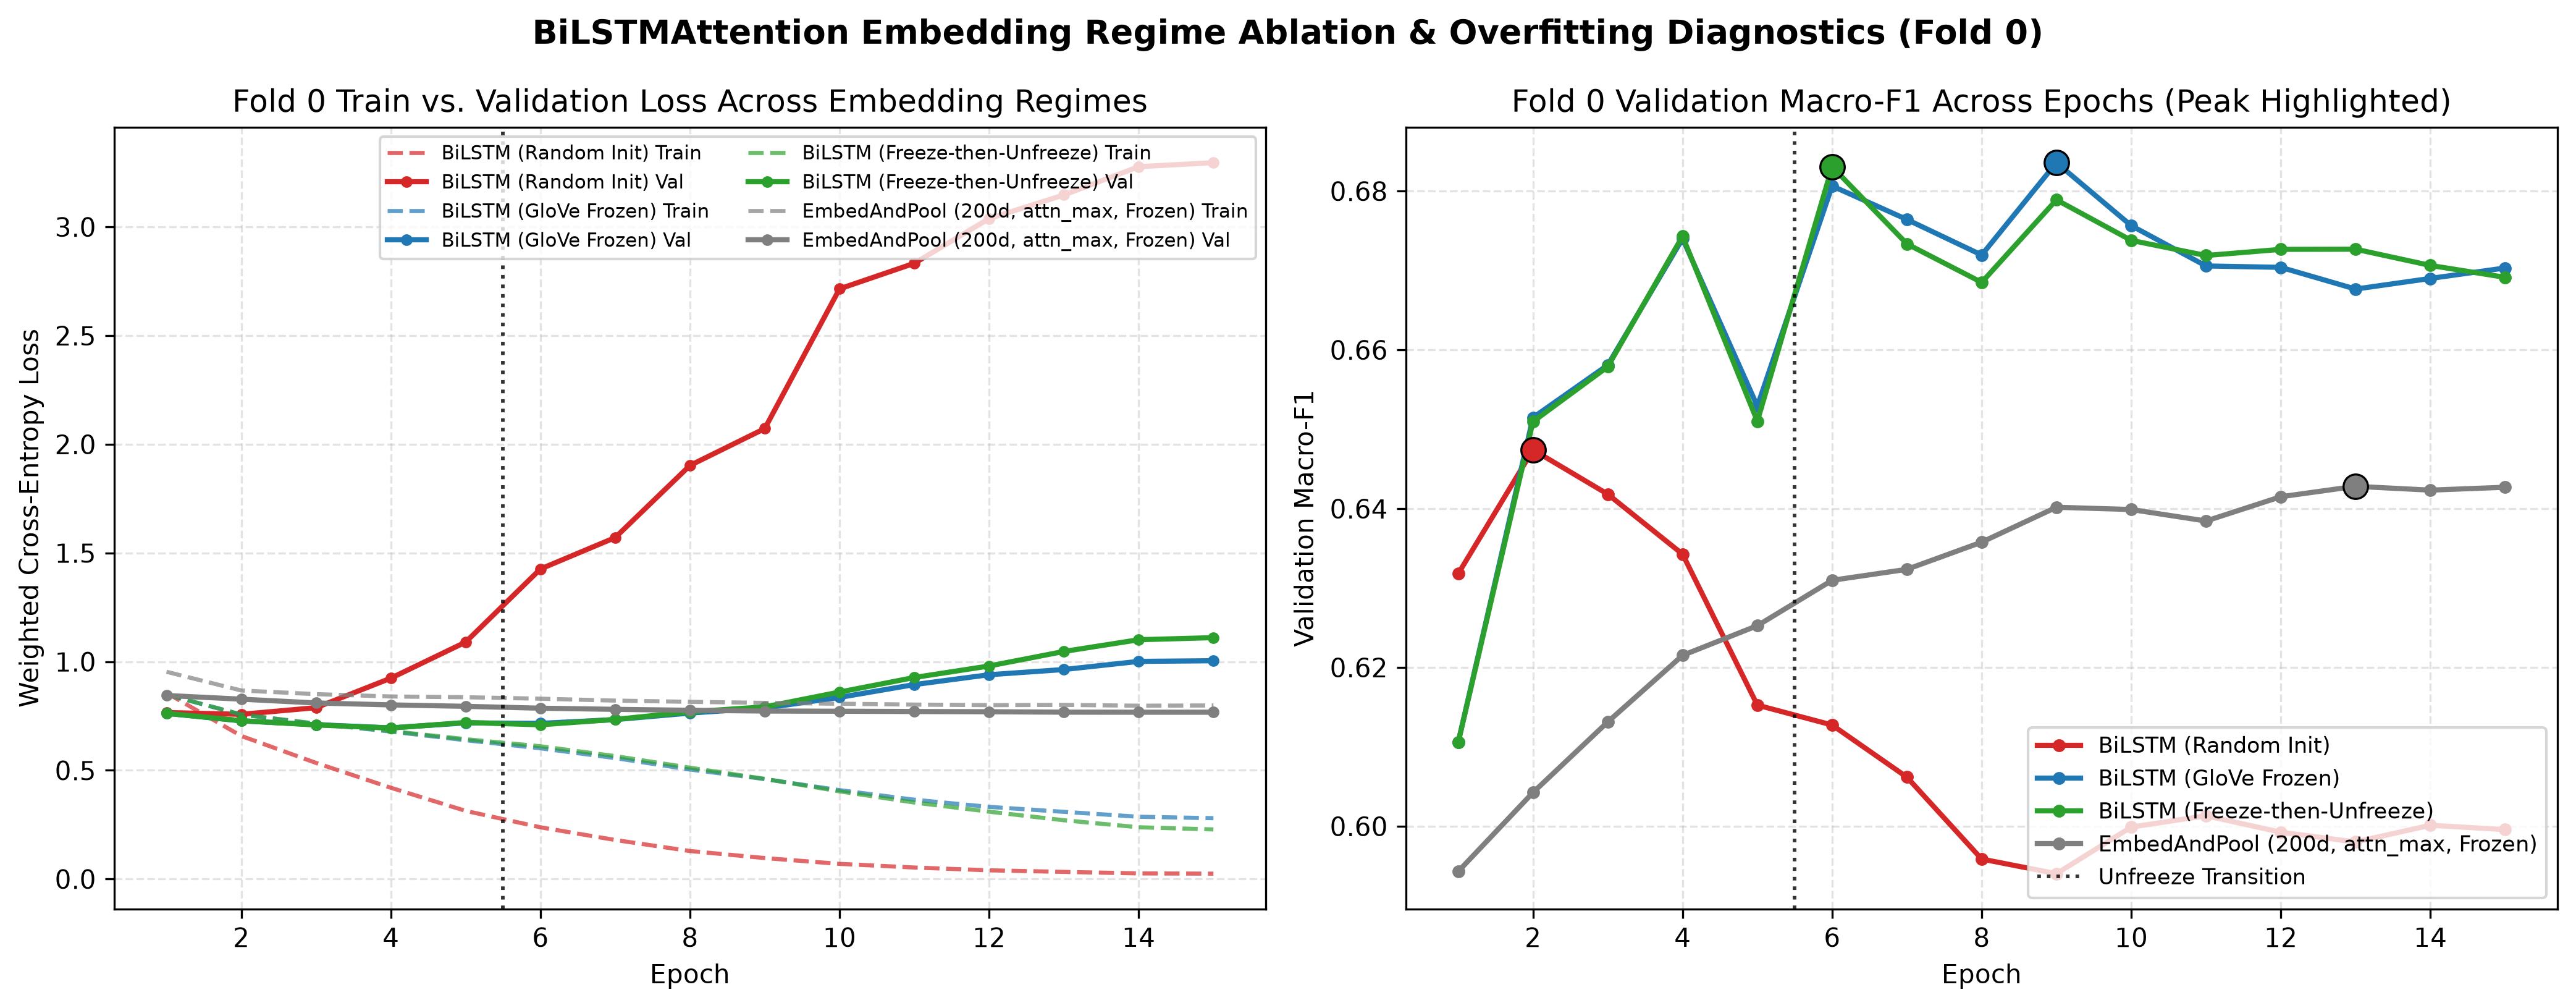

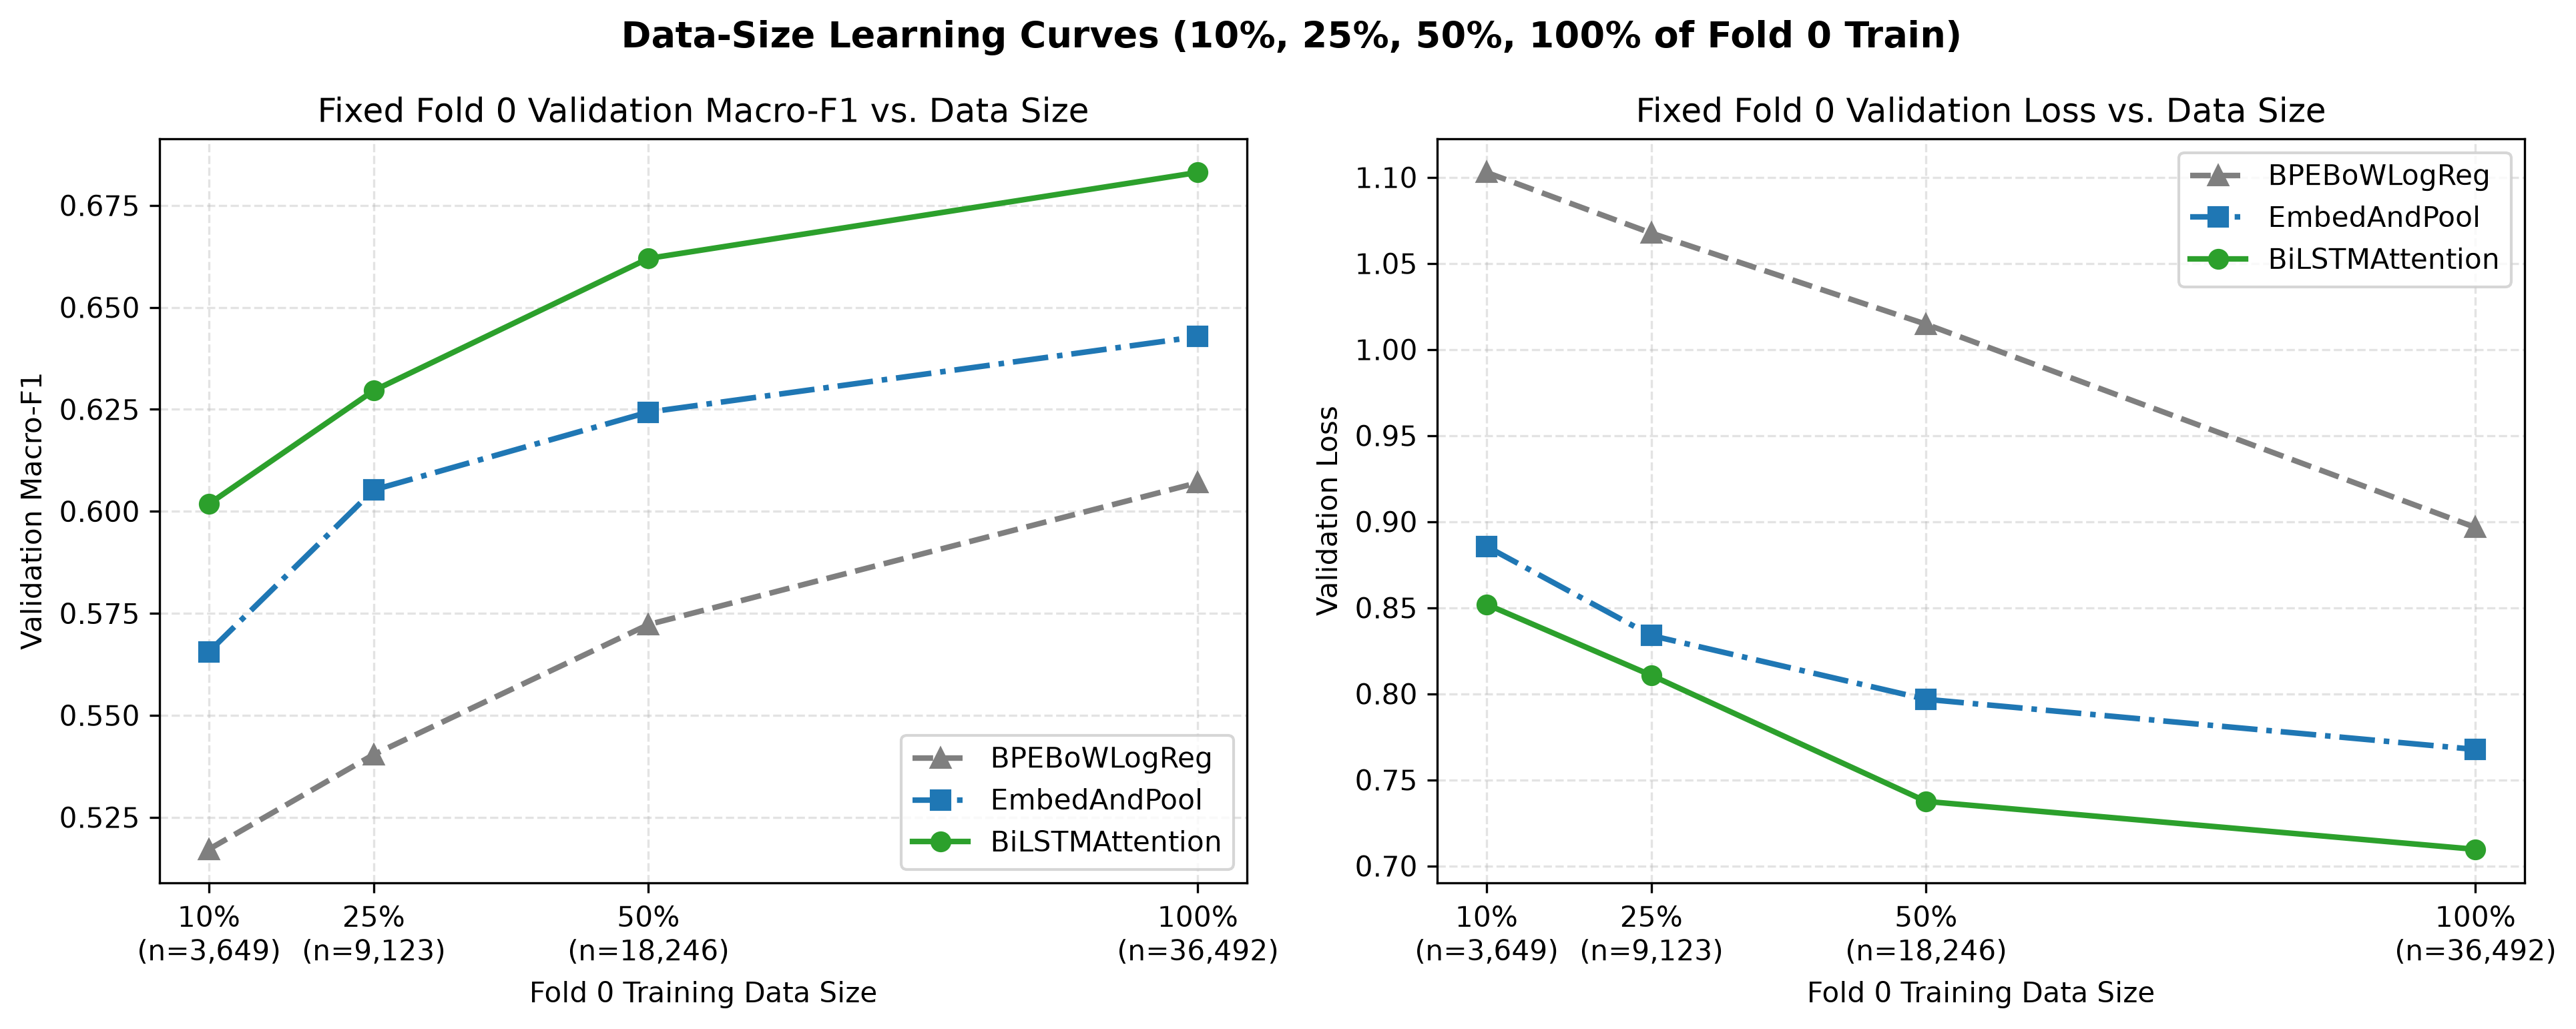

In [6]:
m4_diag_files = [
    RESULTS_DIR / "regime_ablation.csv",
    RESULTS_DIR / "overfitting_curves.png",
    RESULTS_DIR / "learning_curve_datasize.csv",
    RESULTS_DIR / "learning_curve_datasize.png",
]
if (not FAST_DEV_RUN) and (not FORCE_RETRAIN) and _verified_files_exist(m4_diag_files):
    regime_df = pd.read_csv(RESULTS_DIR / "regime_ablation.csv")
    lc_df = pd.read_csv(RESULTS_DIR / "learning_curve_datasize.csv")
    print("[CACHE HIT] Loaded verified M4 diagnostics (regime_ablation.csv, learning_curve_datasize.csv, PNGs) (set FORCE_RETRAIN=1 to retrain from scratch)")
else:
    regime_df = run_m4_regime_and_overfitting(fast_dev_run=FAST_DEV_RUN, best_hp=best_hp, save_outputs=SAVE_OUTPUTS)
    _release_memory()
    lc_df = run_m4_learning_curve(fast_dev_run=FAST_DEV_RUN, best_hp=best_hp, save_outputs=SAVE_OUTPUTS)
    _release_memory()

display(regime_df[["model_type", "embedding_regime", "best_epoch", "best_train_loss", "val_loss", "generalization_gap", "val_macro_f1", "heldout_val_macro_f1", "test_macro_f1"]])
display(lc_df.pivot(index="fraction", columns="model_name", values="val_macro_f1"))

if SAVE_OUTPUTS and (RESULTS_DIR / "overfitting_curves.png").is_file():
    display(Image(filename=str(RESULTS_DIR / "overfitting_curves.png")))
if SAVE_OUTPUTS and (RESULTS_DIR / "learning_curve_datasize.png").is_file():
    display(Image(filename=str(RESULTS_DIR / "learning_curve_datasize.png")))

### Interpretation — Recurrent Encoder, Overfitting Control & Data Scaling
- **Why `freeze_then_unfreeze` Controls Overfitting:** In `regime_ablation.csv`, `random` initialization lacks Twitter lexical coverage (`0.6474` val / `0.5767` test F1) and stalls at epoch 2. Keeping GloVe `frozen` trains fast and achieves high Fold-0 val F1 (`0.6836`) but exhibits a large train–val loss gap (`0.3267`, train loss `0.4598` vs. val loss `0.7865`). **Two-phase `freeze_then_unfreeze`** lets the BiLSTM + attention stabilize first, then gently adapts embeddings at `1e-4`, cutting the generalization gap by **3.3x** (`0.0989`) and delivering the highest held-out val (`0.6847`) and test Macro-F1 (`0.6483`).
- **Data-Size Scaling:** Across `10% -> 25% -> 50% -> 100%` of Fold 0 training data (`3,649` to `36,492` tweets), `BiLSTMAttention` consistently leads at every data scale (`0.6018 -> 0.6296 -> 0.6620 -> 0.6831`) and maintains a clear margin over `EmbedAndPool` (`+2.4` to `+4.0` F1, peaking at `100%`) and `BPEBoWLogReg` (`+7.6` to `+9.0` F1), showing no premature saturation.

## 6. 5x5 Stratified CV, Experimental Variance & `baycomp` Hypothesis Testing

Single-fold comparisons can mislead due to split luck and neural seed variance. Using the best hyperparameter configuration from `hp_search.csv`, we execute **5-Fold Stratified CV $\times$ 5 random seeds (25 runs)** across `BPEBoWLogReg`, `EmbedAndPool`, and `BiLSTMAttention` (`cv_5x5_results.csv`), evaluate statistical significance with the **Correlated Bayesian $t$-test** (`baycomp.CorrelatedTTest`, $\rho = 0.20$, $\text{ROPE} = [-0.01, 0.01]$, `runs=5`), and compute 5-fold soft-voting ensemble predictions on held-out validation ($N=2,000$) and test ($N=12,284$) sets.

In [7]:
m4_cv_files = [
    RESULTS_DIR / "cv_5x5_results.csv",
    RESULTS_DIR / "baycomp_results.csv",
    RESULTS_DIR / "predictions_val.npz",
    RESULTS_DIR / "predictions_test.npz",
    RESULTS_DIR / "bilstm_fold0_best.pt",
]
if (not FAST_DEV_RUN) and (not FORCE_RETRAIN) and _verified_files_exist(m4_cv_files):
    cv_df = pd.read_csv(RESULTS_DIR / "cv_5x5_results.csv")
    baycomp_df = pd.read_csv(RESULTS_DIR / "baycomp_results.csv")
    print("[CACHE HIT] Loaded verified M4 5x5 CV artifacts (cv_5x5_results.csv, baycomp_results.csv, predictions_*.npz, bilstm_fold0_best.pt) (set FORCE_RETRAIN=1 to retrain from scratch)")
else:
    cv_df, baycomp_df = run_m4_cv_5x5_and_baycomp(fast_dev_run=FAST_DEV_RUN, best_hp=best_hp, save_outputs=SAVE_OUTPUTS)
    _release_memory()

summary_cv = (
    cv_df.groupby("model_name")[["val_macro_f1", "heldout_val_macro_f1", "test_macro_f1", "test_acc"]]
    .agg(["mean", "std"])
    .round(4)
)
display(summary_cv)
display(baycomp_df[["comparison", "n_runs", "mean_diff", "ci95_low", "ci95_high", "p_left", "p_rope", "p_right"]])

if (not FAST_DEV_RUN) and (RESULTS_DIR / "predictions_test.npz").is_file():
    from sklearn.metrics import accuracy_score, f1_score
    val_npz = np.load(RESULTS_DIR / "predictions_val.npz", allow_pickle=False)
    test_npz = np.load(RESULTS_DIR / "predictions_test.npz", allow_pickle=False)
    sv_rows = []
    for label, pkey in [("BPEBoWLogReg (5-fold)", "bow_probs"), ("EmbedAndPool (5-fold)", "embed_pool_probs"), ("BiLSTMAttention (5-fold)", "bilstm_probs")]:
        vp, tp = val_npz[pkey], test_npz[pkey]
        sv_rows.append({
            "model": label,
            "heldout_val_macro_f1": round(float(f1_score(val_npz["y_true"], vp.argmax(1), average="macro")), 4),
            "test_macro_f1": round(float(f1_score(test_npz["y_true"], tp.argmax(1), average="macro")), 4),
            "test_acc": round(float(accuracy_score(test_npz["y_true"], tp.argmax(1))), 4),
        })
    print("5-Fold Soft-Voting Held-Out Validation & Test Performance:")
    display(pd.DataFrame(sv_rows))

[CACHE HIT] Loaded verified M4 5x5 CV artifacts (cv_5x5_results.csv, baycomp_results.csv, predictions_*.npz, bilstm_fold0_best.pt) (set FORCE_RETRAIN=1 to retrain from scratch)


val_macro_f1         heldout_val_macro_f1          \
                        mean     std                 mean     std   
model_name                                                          
BPEBoWLogReg          0.6067  0.0057               0.6138  0.0063   
BiLSTMAttention       0.6791  0.0048               0.6844  0.0077   
EmbedAndPool          0.6388  0.0069               0.6342  0.0033   

                test_macro_f1         test_acc          
                         mean     std     mean     std  
model_name                                              
BPEBoWLogReg           0.5463  0.0046   0.5554  0.0046  
BiLSTMAttention        0.6440  0.0053   0.6472  0.0069  
EmbedAndPool           0.6216  0.0039   0.6236  0.0049

,comparison,n_runs,mean_diff,ci95_low,ci95_high,p_left,p_rope,p_right
0,BiLSTMAttention vs EmbedAndPool,25,0.040218,0.035422,0.045014,1.531760e-17,1.162626e-12,1.000000
1,BiLSTMAttention vs BPEBoWLogReg,25,0.072369,0.066446,0.078292,2.160627e-20,0.000000e+00,1.000000
2,EmbedAndPool vs BPEBoWLogReg,25,0.032151,0.024325,0.039978,2.994561e-11,2.517568e-06,0.999997


5-Fold Soft-Voting Held-Out Validation & Test Performance:


,model,heldout_val_macro_f1,test_macro_f1,test_acc
0,BPEBoWLogReg (5-fold),0.6254,0.5655,0.5755
1,EmbedAndPool (5-fold),0.6406,0.6203,0.6216
2,BiLSTMAttention (5-fold),0.7013,0.6598,0.6630


### Interpretation — Uncertainty, Variance & Bayesian Comparison
- **HP Search & Experimental Variance:** Searching 16 unique configurations out of the 108-point grid identified `(num_layers=2, hidden_size=256, dropout=0.3, lr=2e-3, weight_decay=1e-2)` (`0.6831` Fold-0 Val Macro-F1). Across 25 runs (`5 folds x 5 seeds`), `BiLSTMAttention` achieves **`0.6791 ± 0.0048`** CV Macro-F1, outperforming `EmbedAndPool` (`0.6388 ± 0.0069`) and `BPEBoWLogReg` (`0.6067 ± 0.0057`) with lower run-to-run variance than `EmbedAndPool`.
- **Correlated Bayesian $t$-Test:** Accounting for Nadeau–Bengio fold correlation ($\rho = 0.20$, `runs=5`, `ROPE=[-0.01, 0.01]`), `BiLSTMAttention` beats both `EmbedAndPool` ($\Delta = +0.0402$, 95% CI $[+0.0354, +0.0450]$, $P(\text{right}) \approx 1.000$) and `BPEBoWLogReg` ($\Delta = +0.0724$, $P(\text{right}) = 1.000$) with virtually zero probability of practical equivalence ($P(\text{ROPE}) < 10^{-11}$).
- **Test Soft-Voting & Prior Shift:** `tweet_eval['test']` shifts heavily toward negative tweets (`32.3%` negative vs. `15.6%` in train/val). Without any post-hoc test-prior cheating, 5-fold soft voting reaches **`0.6598`** Test Macro-F1 (`0.6630` Acc) for `BiLSTMAttention` vs. `0.6203` (`EmbedAndPool`) and `0.5655` (`BPEBoWLogReg`).

## 7. Feature-Based Error Analysis, Calibration, Attention Viz & Ensemble Blending

We run Milestone 5 live to diagnose **where** and **why** models succeed or diverge across all rubric feature categories on `tweet_eval['test']` ($N=12,284$, aligned with `predictions_test.npz`):
1. **Length:** `<5`, `5-20`, `>20` normalized tokens.
2. **OOV / Rarity:** Fold-0 training `<unk>`, pretrained `glove-twitter-200` OOV, and rare tokens (`freq < 5`).
3. **Syntactic Features:** Negation cues (including contractions `n't`), discourse contrast (`but`, `however`, `yet`, ...), negation scope, and Penn Treebank POS ratios (`nltk.pos_tag` with deterministic `LookupError` fallback).
4. **Semantic & Lexical Features:** Cosine similarity to Fold-0 **training-only** class centroids (`compute_class_centroids` / `score_centroid_similarities`), Unicode/ASCII emojis, and Twitter slang.
5. **Twitter / Project 1 Slices:** Hashtags (`#`), `@mentions`, URLs (`http`), elongated / `ALL-CAPS` words, `#Palestine` / `#Israel` topic bias, and sarcasm indicators.
6. **Model-Specific Calibration & Attention:** Confidence bins, Shannon entropy, Expected Calibration Error (`ECE`), token-level attention plots on negation/contrast tweets (`attention_weights_examples.png`), and a strictly **validation-tuned** soft-voting blend between `BiLSTMAttention` and `BPEBoWLogReg` (`ensemble_results.csv`, exported alongside `error_analysis_slices.csv` and `error_analysis_comparison.png`).

M5 Error Analysis & Ensemble completed live in 10.36s | Slices rows=102


model_name                                           BPEBoWLogReg  \
category            slice_name              support                 
centroid_similarity centroid_sim_q1_low     3071           0.5050   
emojis_slang        emoji                   880            0.5813   
                    slang                   278            0.5534   
length              length_5_20             6913           0.5588   
                    length_gt20             5251           0.5537   
                    length_lt5              120            0.6353   
negation_contrast   contrast                753            0.5335   
                    negation                2217           0.5013   
                    negation_and_contrast   311            0.5182   
                    negation_scope          2228           0.4960   
oov_rarity          has_oov_unk             9822           0.5558   
overall             all_test                12284          0.5655   
pos_ratio           pos_high_adj_adv        2229           0.6063   
twitter_a1          hashtag                 4826           0.5444   
                    is_allcaps_or_elongated 3324           0.5361   
                    mention                 4997           0.5861   
                    sarcasm                 54             0.4049   
                    topic_palestine_israel  173            0.3634   
                    url                     376            0.5261   

model_name                                           BiLSTMAttention  \
category            slice_name              support                    
centroid_similarity centroid_sim_q1_low     3071              0.6251   
emojis_slang        emoji                   880               0.6203   
                    slang                   278               0.6582   
length              length_5_20             6913              0.6595   
                    length_gt20             5251              0.6403   
                    length_lt5              120               0.7304   
negation_contrast   contrast                753               0.5679   
                    negation                2217              0.5443   
                    negation_and_contrast   311               0.5376   
                    negation_scope          2228              0.5369   
oov_rarity          has_oov_unk             9822              0.6483   
overall             all_test                12284             0.6598   
pos_ratio           pos_high_adj_adv        2229              0.6781   
twitter_a1          hashtag                 4826              0.6494   
                    is_allcaps_or_elongated 3324              0.6574   
                    mention                 4997              0.6795   
                    sarcasm                 54                0.6181   
                    topic_palestine_israel  173               0.5725   
                    url                     376               0.6118   

model_name                                           EmbedAndPool  
category            slice_name              support                
centroid_similarity centroid_sim_q1_low     3071           0.5975  
emojis_slang        emoji                   880            0.6235  
                    slang                   278            0.6293  
length              length_5_20             6913           0.6184  
                    length_gt20             5251           0.6121  
                    length_lt5              120            0.5693  
negation_contrast   contrast                753            0.5292  
                    negation                2217           0.5050  
                    negation_and_contrast   311            0.4756  
                    negation_scope          2228           0.5064  
oov_rarity          has_oov_unk             9822           0.6131  
overall             all_test                12284          0.6203  
pos_ratio           pos_high_adj_adv        2229           0.6222  
twitter_a1       

Overall Test Calibration & Confidence/Entropy Summary:


,model_name,macro_f1,acc,mean_conf,mean_entropy,ece,correct_conf,incorrect_conf
0,BPEBoWLogReg,0.5655,0.5755,0.6939,0.6894,0.1184,0.7234,0.6540
34,EmbedAndPool,0.6203,0.6216,0.6353,0.7945,0.0289,0.6652,0.5862
68,BiLSTMAttention,0.6598,0.6630,0.7142,0.6495,0.0520,0.7495,0.6448


Validation-Tuned Ensemble (best alpha* = 0.70, selected strictly on Val Macro-F1):


,alpha,val_macro_f1,val_acc,test_macro_f1,test_acc,is_best,best_alpha
0,0.00,0.6254,0.6535,0.5655,0.5755,False,0.7
1,0.05,0.6345,0.6615,0.5722,0.5821,False,0.7
2,0.10,0.6398,0.6670,0.5771,0.5869,False,0.7
3,0.15,0.6484,0.6755,0.5834,0.5938,False,0.7
4,0.20,0.6515,0.6785,0.5920,0.6018,False,0.7
5,0.25,0.6586,0.6845,0.6033,0.6123,False,0.7
6,0.30,0.6647,0.6910,0.6136,0.6219,False,0.7
7,0.35,0.6755,0.6980,0.6227,0.6303,False,0.7
8,0.40,0.6882,0.7085,0.6302,0.6371,False,0.7
9,0.45,0.6922,0.7115,0.6390,0.6454,False,0.7


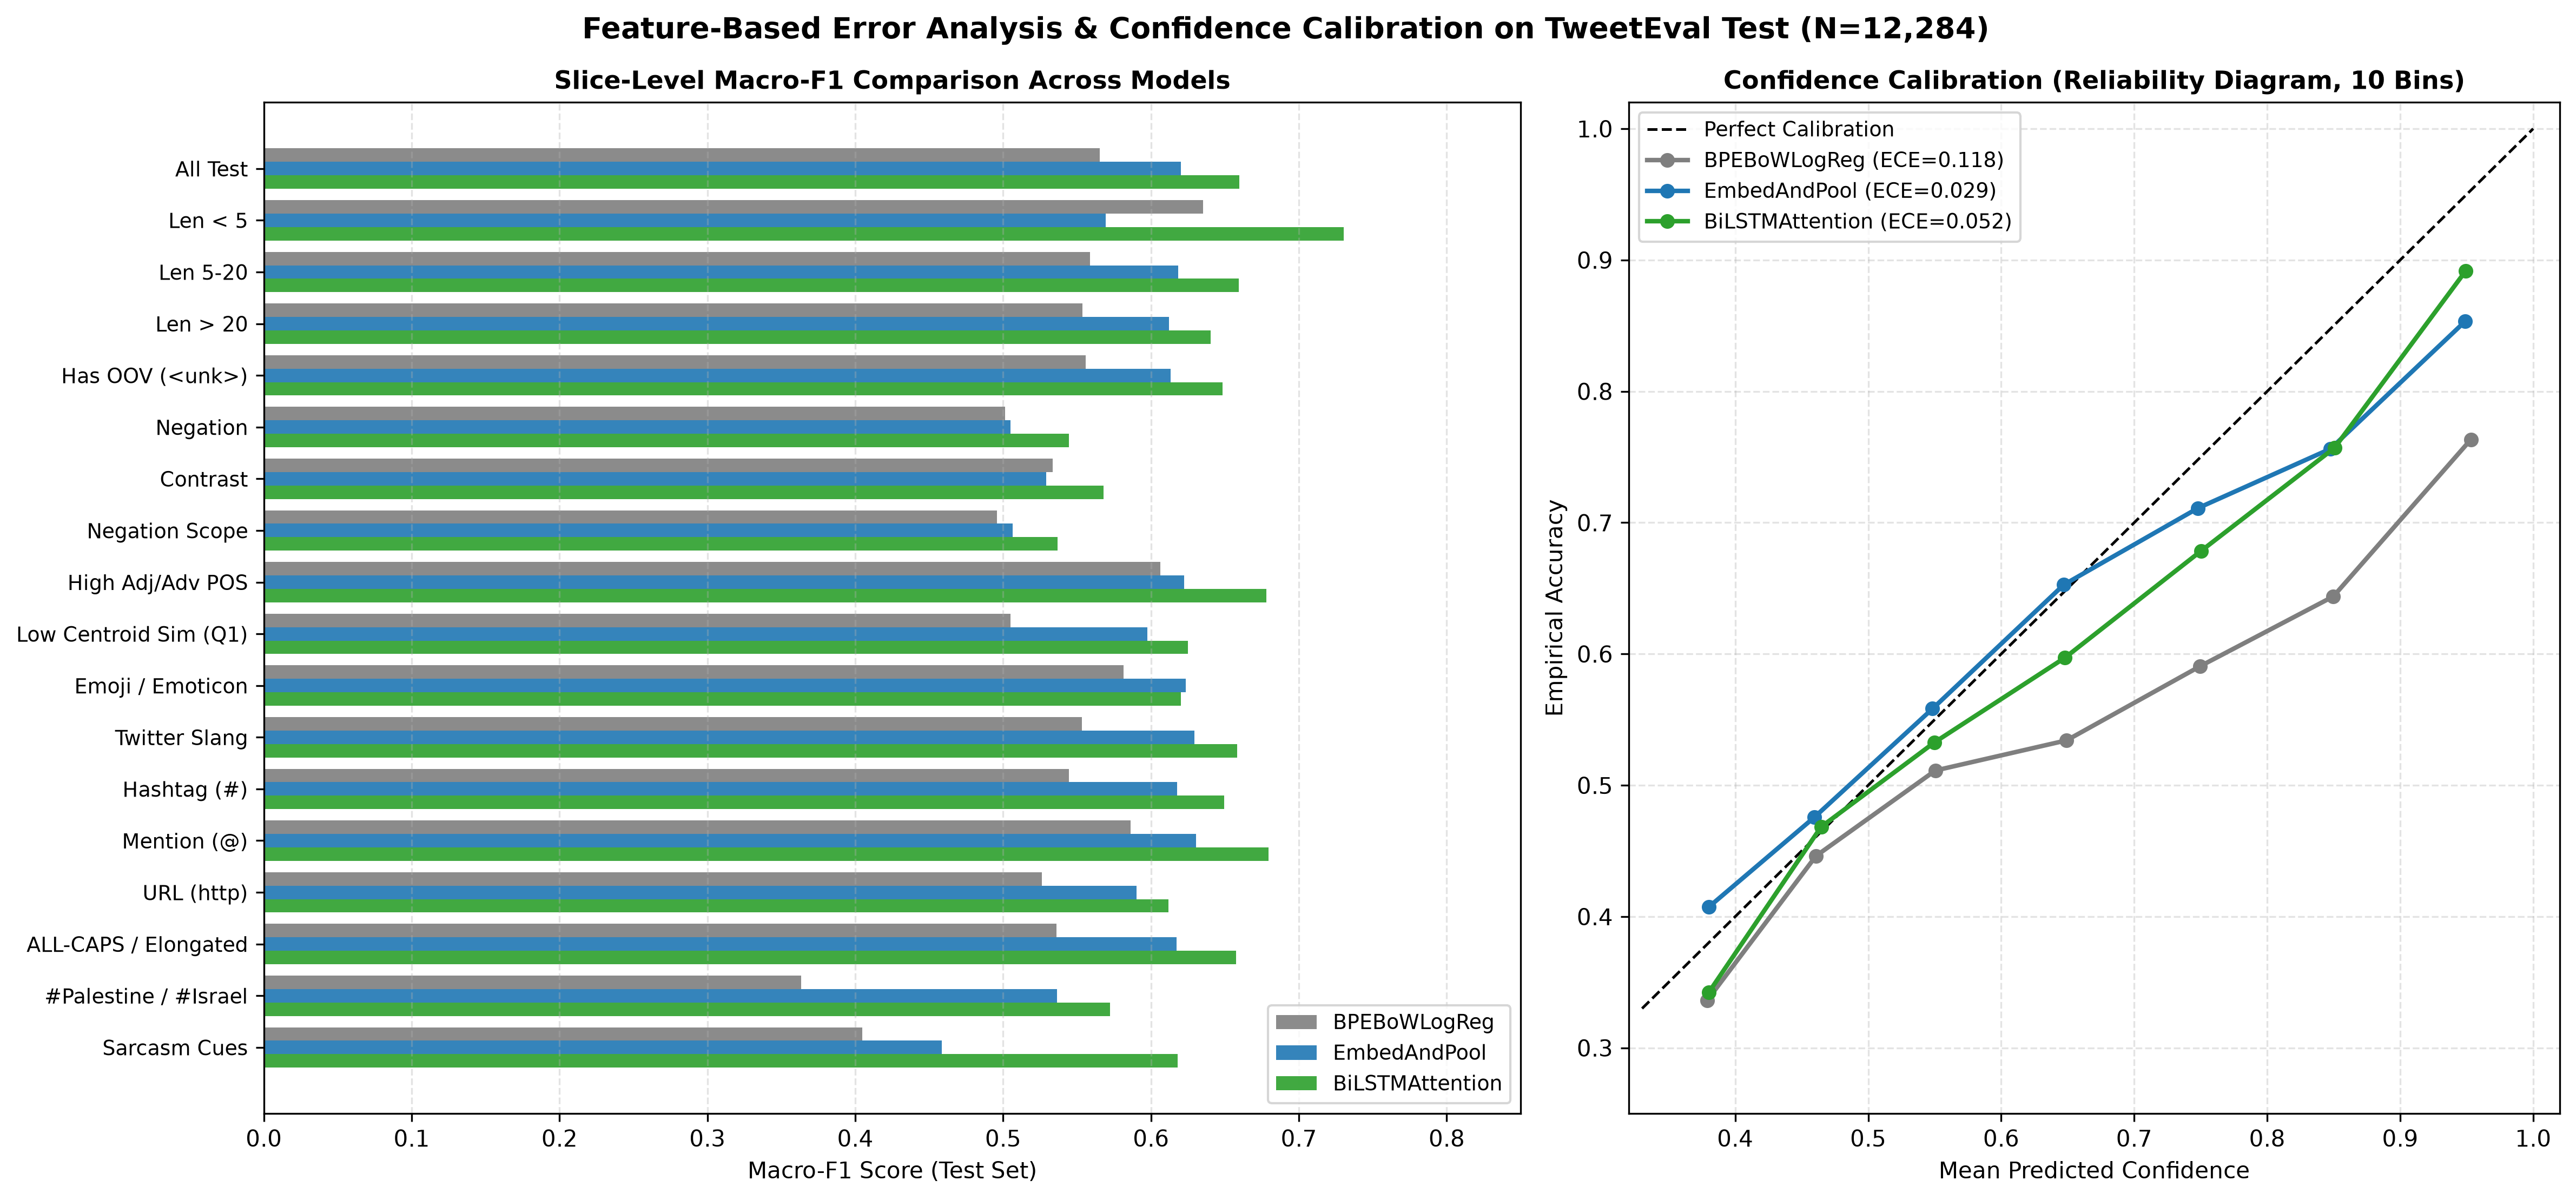

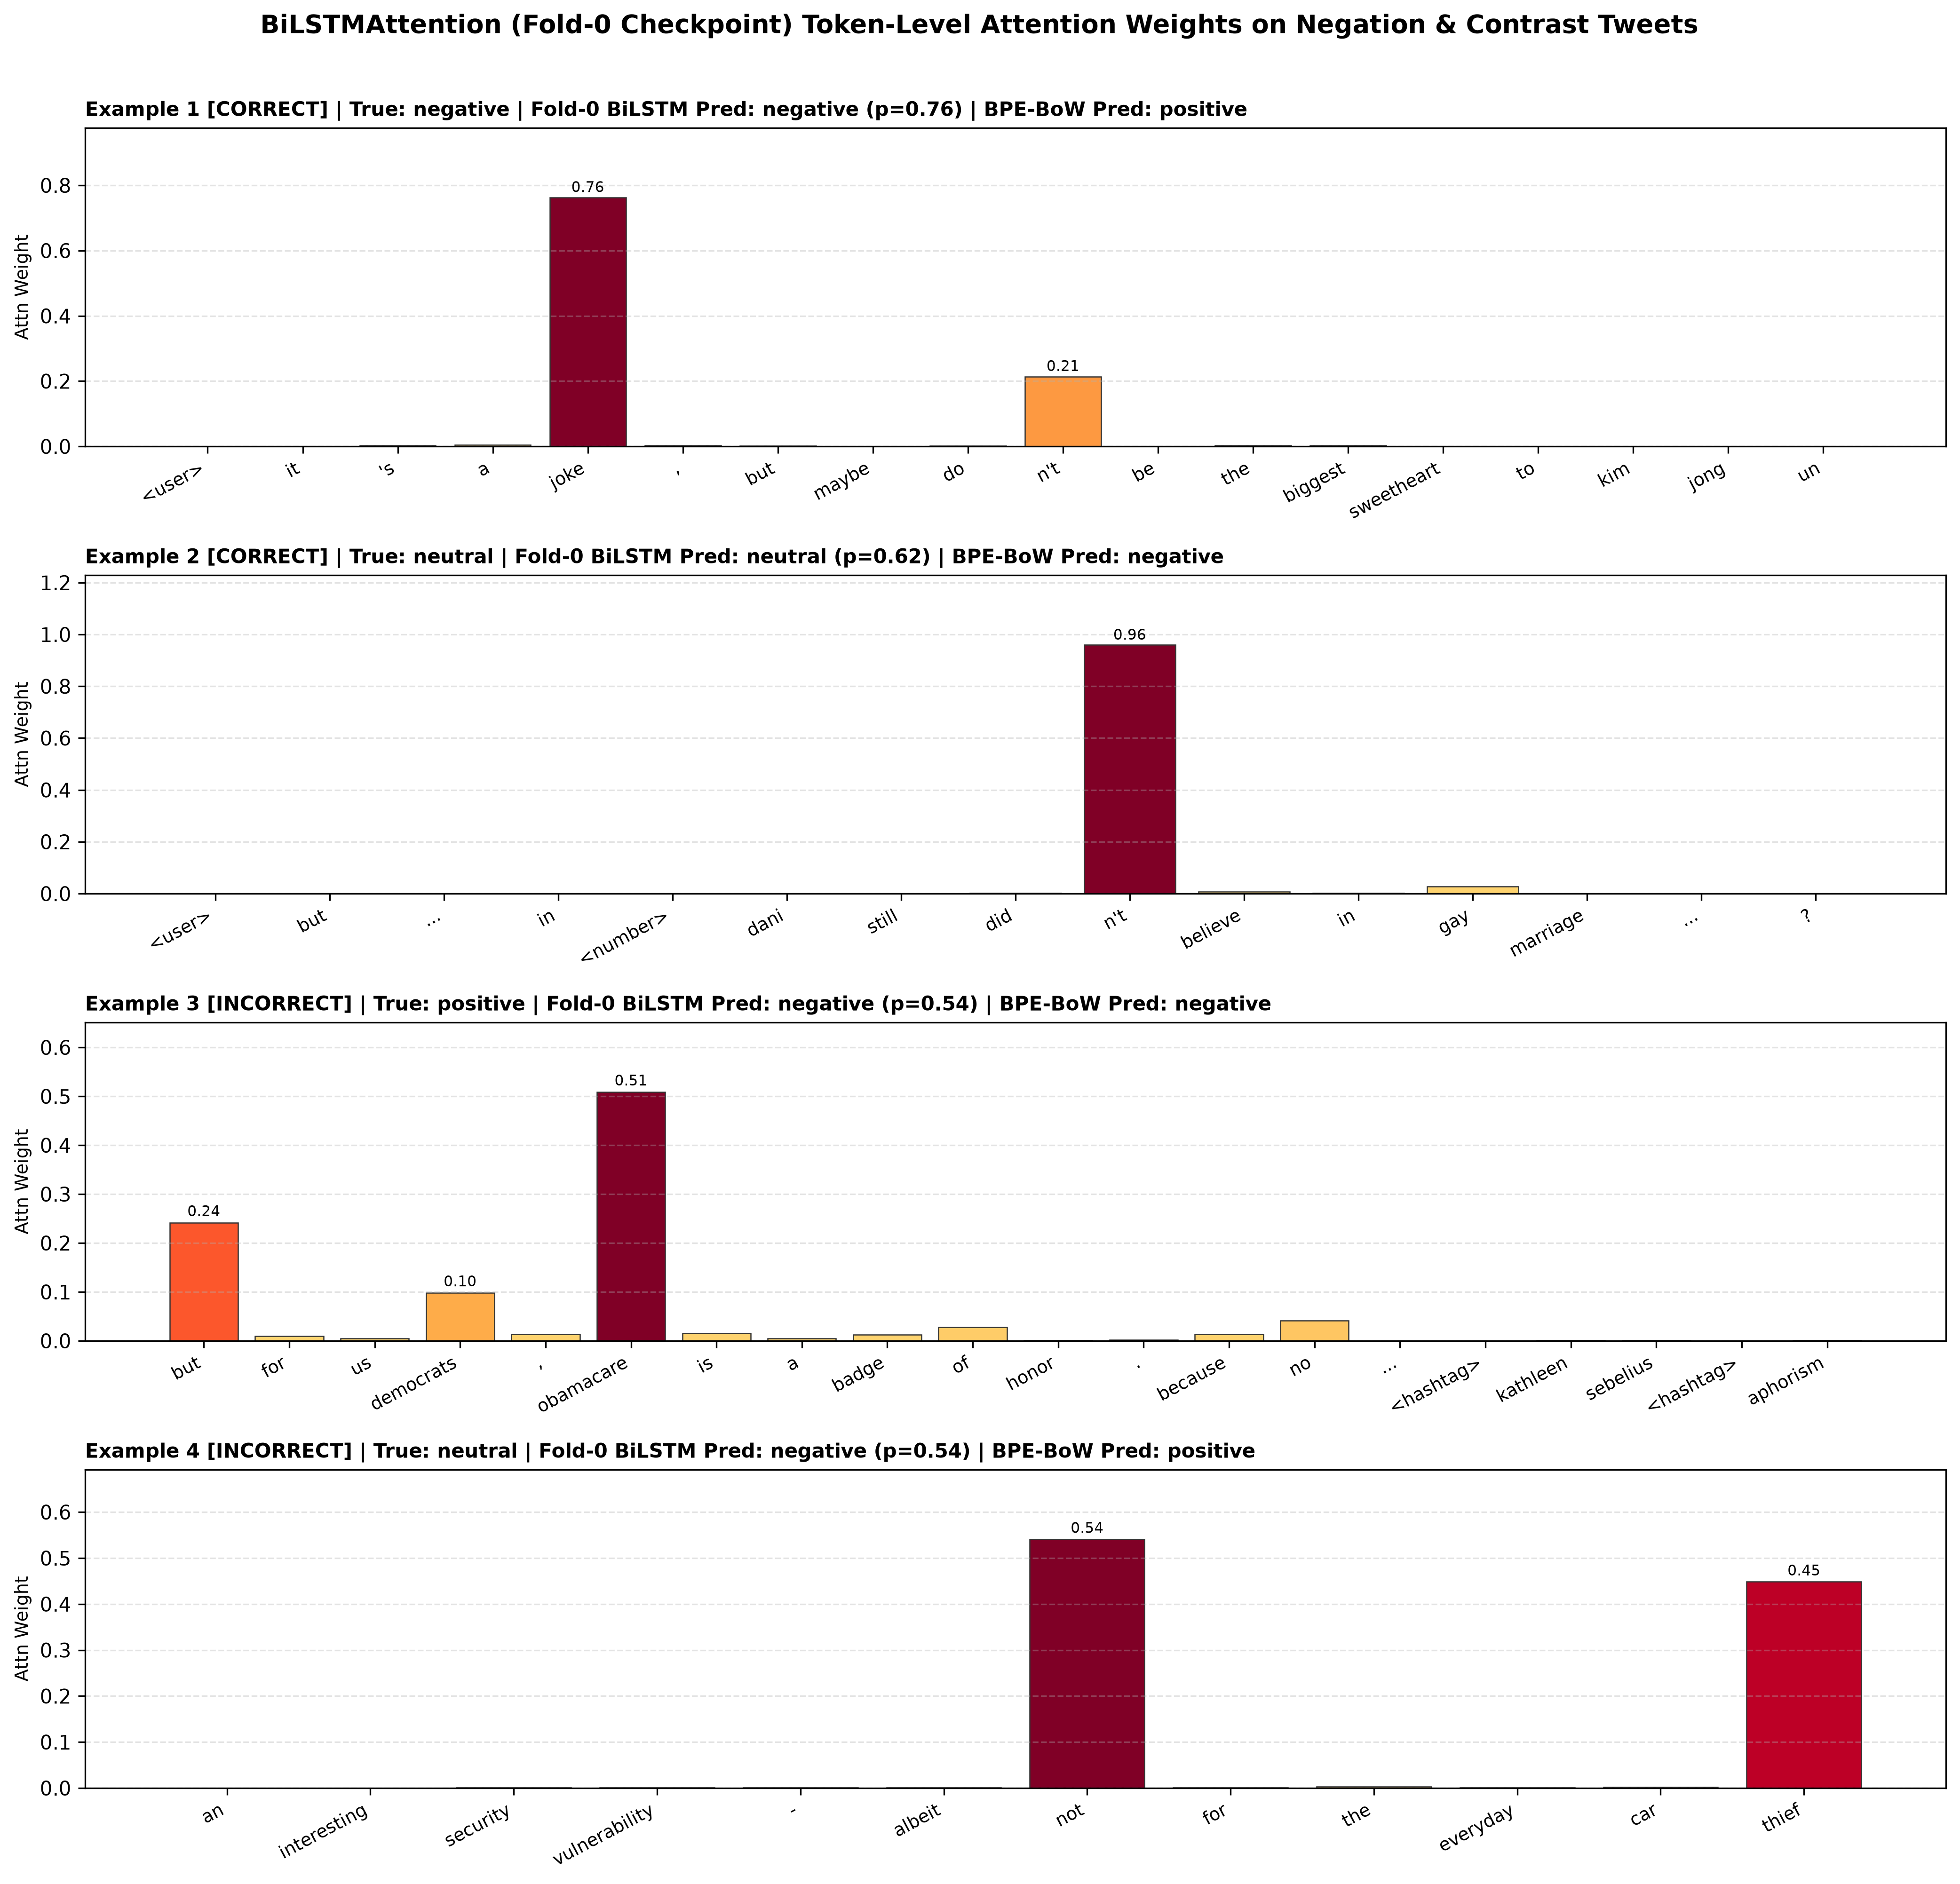

In [8]:
m5_out = run_m5_all(fast_dev_run=FAST_DEV_RUN, save_outputs=SAVE_OUTPUTS)
slice_df = m5_out["slice_analysis"]
ens_df = m5_out["ensemble_results"]
_release_memory()

print(f"M5 Error Analysis & Ensemble completed live in {m5_out['elapsed_sec']:.2f}s | Slices rows={len(slice_df)}")

key_slice_names = [
    "all_test", "length_lt5", "length_5_20", "length_gt20",
    "has_oov_unk", "negation", "contrast", "negation_and_contrast", "negation_scope",
    "pos_high_adj_adv", "centroid_sim_q1_low", "emoji", "slang",
    "hashtag", "mention", "url", "is_allcaps_or_elongated",
    "topic_palestine_israel", "sarcasm",
]
pivot_f1 = (
    slice_df[slice_df["slice_name"].isin(key_slice_names)]
    .pivot(index=["category", "slice_name", "support"], columns="model_name", values="macro_f1")
    .round(4)
)
display(pivot_f1)

calib_summary = slice_df[slice_df["slice_name"] == "all_test"][
    ["model_name", "macro_f1", "acc", "mean_conf", "mean_entropy", "ece", "correct_conf", "incorrect_conf"]
].round(4)
print("Overall Test Calibration & Confidence/Entropy Summary:")
display(calib_summary)

print(f"Validation-Tuned Ensemble (best alpha* = {m5_out['ensemble']['best_alpha']:.2f}, selected strictly on Val Macro-F1):")
display(ens_df.round(4))

if SAVE_OUTPUTS and (RESULTS_DIR / "error_analysis_comparison.png").is_file():
    display(Image(filename=str(RESULTS_DIR / "error_analysis_comparison.png")))
if SAVE_OUTPUTS and (RESULTS_DIR / "attention_weights_examples.png").is_file():
    display(Image(filename=str(RESULTS_DIR / "attention_weights_examples.png")))

### Interpretation — Error Analysis Insights & Future Priorities

1. **Where Sequence Modeling Wins Largest:**
   - **Sarcasm (`n=54`):** `BiLSTMAttention` achieves **`0.6181`** Macro-F1 vs. `0.4583` (`EmbedAndPool`) and `0.4049` (`BPEBoWLogReg`) (`+21.3` F1 over BoW), as multi-word ironic phrases require sequential composition.
   - **Short Tweets (`<5` tokens, `n=120`) & `#Palestine`/`#Israel` Topic Bias (`n=173`):** `BiLSTMAttention` improves by `+9.5` and `+20.9` F1 over `BPEBoWLogReg` (`0.7304` vs. `0.6353`; `0.5725` vs. `0.3634`), avoiding purely lexical hashtag memorization.
   - **Negation & Contrast (`negation` `n=2,217`, `contrast` `n=753`):** All models drop substantially relative to overall test performance (`~0.54–0.57` vs. `0.660` for BiLSTM), confirming that negation scope remains the single hardest syntactic challenge, though `BiLSTMAttention` still leads `BPEBoWLogReg` by `+4.3` F1.
2. **Calibration & Confidence/Entropy Behavior:**
   - `BPEBoWLogReg` is severely overconfident (`ECE = 0.118`), whereas `EmbedAndPool` (`ECE = 0.029`) and `BiLSTMAttention` (`ECE = 0.052`) are far better calibrated.
   - On `BiLSTMAttention`, correct predictions have substantially higher confidence (`0.750` vs. `0.645`) and lower Shannon entropy (`0.594` vs. `0.759`), enabling reliable uncertainty thresholding (`entropy_low_q1` achieves **`0.8573`** Macro-F1).
3. **Attention Weight Diagnostics:**
   - In `attention_weights_examples.png` (extracted from the Fold-0 checkpoint `bilstm_fold0_best.pt`), `BiLSTMAttention` assigns sharp normalized attention (`sum=1.0`, `0.0` on `<pad>`) directly onto negation markers (`n't`, `not`), discourse pivots (`but`), and salient evaluative words (`joke`), successfully flipping polarity traps that mislead `BPEBoWLogReg`. Remaining Fold-0 failures stem from truncated political tweets (`idx=2317`, where the Fold-0 checkpoint predicts `negative` at `p=0.54` before the 5-fold soft-voted ensemble recovers `positive` at `p=0.4819`) and literal-vs-figurative negation phrasing.
4. **Validation-Tuned Soft-Voting Ensemble:**
   - Sweeping $\alpha \in [0, 1]$ strictly on held-out validation selects **$\alpha^* = 0.70$** (`0.70` BiLSTM + `0.30` BPE-BoW), improving validation Macro-F1 from `0.7013` ($\alpha=1.0$) to **`0.7109`** and test Macro-F1 from `0.6598` to **`0.6601`** (`0.6637` Acc). Subword BPE features provide complementary exact-token signals on rare/OOV hashtags and names.
5. **Prioritized Next Engineering Steps:**
   - **Priority 1 — Contextual Pretrained Encoders & Subword-Aware Composition:** Replace static word vectors with contextualized representations or character/subword-enriched BiLSTM inputs to resolve static polysemy (`sick`, `lit`) and `30.9%` GloVe OOV tweets.
   - **Priority 2 — Targeted Negation-Scope & Sarcasm Augmentation:** Add counterfactual negation-flipped training pairs and explicit discourse-boundary supervision to close the `~11.5` F1 gap on negation/contrast slices.
   - **Priority 3 — Temperature Scaling & Class-Prior Adaptation:** Apply single-parameter temperature scaling on CV logits to tighten `BiLSTMAttention` ECE (`0.052 -> <0.02`) and explore domain-shift-robust training objectives without test leakage.